# Bu projede, Amazon ürünlerine ait kullanıcı yorumlarını  analiz ederek sentiment tahmininde bulunduk.

In [20]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [21]:
df=pd.read_csv('amazon.csv')

## EDA - Exploratory Data Analysis

In [22]:
df.head()

,Unnamed: 0,reviewerID,asin,reviewerName,helpful,reviewText,overall,summary,unixReviewTime,reviewTime
0,0,AO94DHGC771SJ,0528881469,amazdnu,"[0, 0]",We got this GPS for my husband who is an (OTR)...,5.0,Gotta have GPS!,1.370131e+09,"06 2, 2013"
1,1,AMO214LNFCEI4,0528881469,Amazon Customer,"[12, 15]","I'm a professional OTR truck driver, and I bou...",1.0,Very Disappointed,1.290643e+09,"11 25, 2010"
2,2,A3N7T0DY83Y4IG,0528881469,C. A. Freeman,"[43, 45]","Well, what can I say. I've had this unit in m...",3.0,1st impression,1.283990e+09,"09 9, 2010"
3,3,A1H8PY3QHMQQA0,0528881469,"Dave M. Shaw ""mack dave""","[9, 10]","Not going to write a long review, even thought...",2.0,"Great grafics, POOR GPS",1.290557e+09,"11 24, 2010"
4,4,A24EV6RXELQZ63,0528881469,Wayne Smith,"[0, 0]",I've had mine for a year and here's what we go...,1.0,"Major issues, only excuses for support",1.317254e+09,"09 29, 2011"


In [23]:
df.shape

(11579, 10)

In [24]:
df.isnull().sum()

,0
Unnamed: 0,0
reviewerID,0
asin,0
reviewerName,47
helpful,1
reviewText,7
overall,1
summary,1
unixReviewTime,1
reviewTime,1


In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11579 entries, 0 to 11578
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Unnamed: 0      11579 non-null  int64  
 1   reviewerID      11579 non-null  object 
 2   asin            11579 non-null  object 
 3   reviewerName    11532 non-null  object 
 4   helpful         11578 non-null  object 
 5   reviewText      11572 non-null  object 
 6   overall         11578 non-null  float64
 7   summary         11578 non-null  object 
 8   unixReviewTime  11578 non-null  float64
 9   reviewTime      11578 non-null  object 
dtypes: float64(2), int64(1), object(7)
memory usage: 904.7+ KB


In [26]:
overall=df.groupby('overall').size().reset_index(name='count')
overall['percentage']=(overall['count'] / overall['count'].sum())*100
overall

,overall,count,percentage
0,1.0,633,5.467266
1,2.0,493,4.258076
2,3.0,969,8.369321
3,4.0,2467,21.307652
4,5.0,7016,60.597685


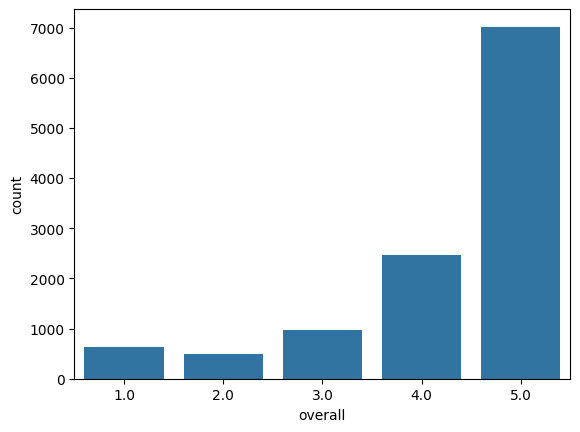

In [27]:
sns.countplot(x=df["overall"]);

## Adding Sentiment Features

In [28]:
df.loc[(df['overall']==1)|(df['overall']==2),'sentiment']='negative'
df.loc[(df['overall']==3),'sentiment']='neutral'
df.loc[(df['overall']==4)|(df['overall']==5),'sentiment']='positive'

In [29]:
df.columns

Index(['Unnamed: 0', 'reviewerID', 'asin', 'reviewerName', 'helpful',
       'reviewText', 'overall', 'summary', 'unixReviewTime', 'reviewTime',
       'sentiment'],
      dtype='object')

In [30]:
df.isnull().sum()

,0
Unnamed: 0,0
reviewerID,0
asin,0
reviewerName,47
helpful,1
reviewText,7
overall,1
summary,1
unixReviewTime,1
reviewTime,1


In [31]:
df = df.drop(['reviewerName', 'reviewTime'], axis=1)

In [32]:
df=df.dropna()

In [33]:
df['reviewText'] = df['reviewText'].str.lower()
df['reviewText'] = df['reviewText'].replace('[^\w\s]', '', regex=True)
df['reviewText'] = df['reviewText'].replace('\n', '', regex=True)
df['reviewText'] = df['reviewText'].replace('\d+', '', regex=True)
df['reviewText'] = df['reviewText'].replace('\r', '', regex=True)

In [34]:
# Yeni bir sütun ekleyerek dilleri tespit etme (ChatGPT den yardım alındı.)

In [35]:
from wordcloud import WordCloud
from wordcloud import STOPWORDS
from PIL import Image #klasörün içerisindeki resimleri okumak için
import numpy as np

In [36]:
def wc(data,bgcolor):
    plt.figure(figsize=(10,10))
    mask=np.array(Image.open('cloud.png'))
    wc=WordCloud(background_color=bgcolor,stopwords=STOPWORDS,mask=mask)
    wc.generate(''.join(data))  # generate --> wordcloud u oluşturmak demek. Bütün sutunlardaki kelimeri alıp birleştirecek ve onların içinden en çok geçen kelimeleri bulup sayacak ve wc'yi oluşturacak
    plt.imshow(wc) #Oluşturduğu resmi göstermesini isteyeceğiz.
    plt.axis('off') # x ve y eksenlerini göstermemesi için.

In [37]:
d={'neutral':0,'negative':1,'positive':2}

In [38]:
df['sentiment']=df['sentiment'].map(d)

In [39]:
neutral=df[df['sentiment']==0]['reviewText']
negative=df[df['sentiment']==1]['reviewText']
positive=df[df['sentiment']==2]['reviewText']

In [40]:
five_stars=df[df['overall'] == 5]['reviewText']

In [41]:
one_stars=df[df['overall'] == 1]['reviewText']

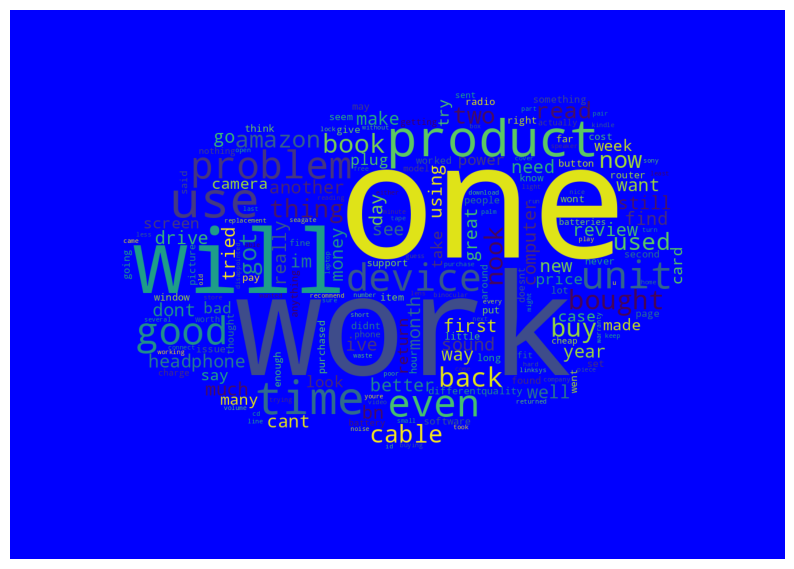

In [42]:
wc(one_stars,'blue')

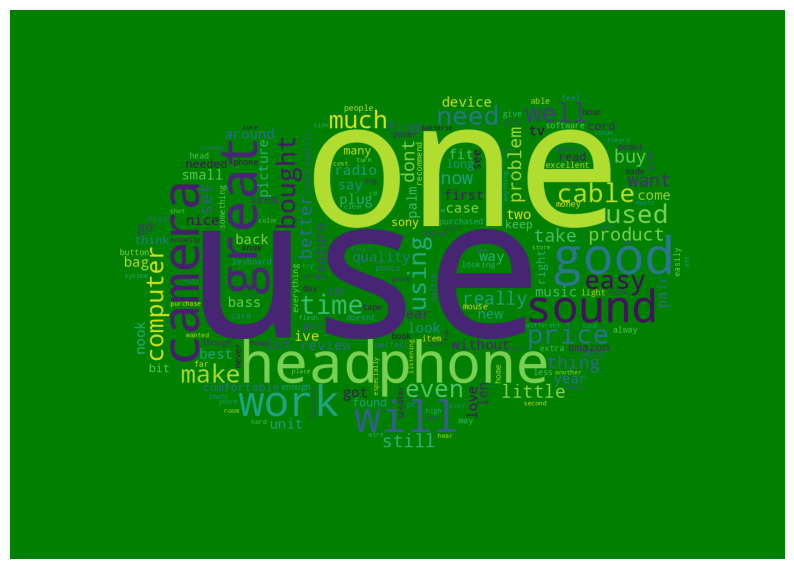

In [43]:
wc(five_stars,'green')

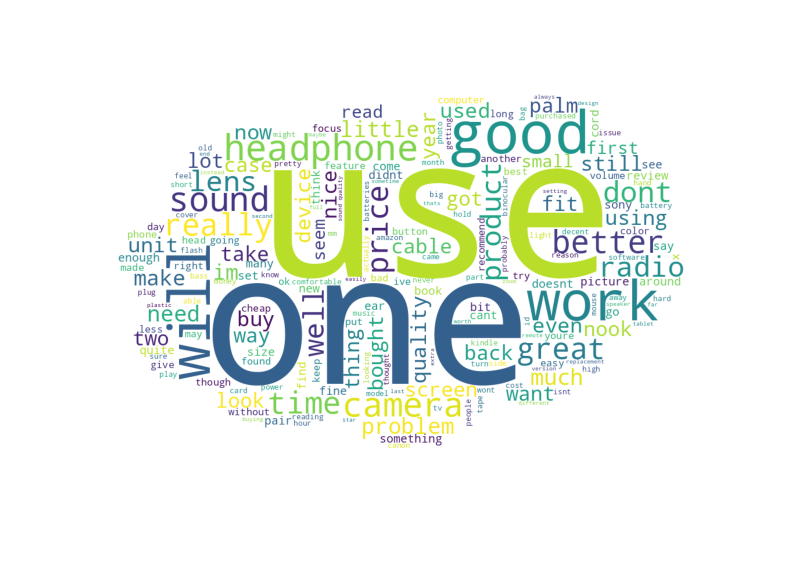

In [44]:
wc(neutral,'white')

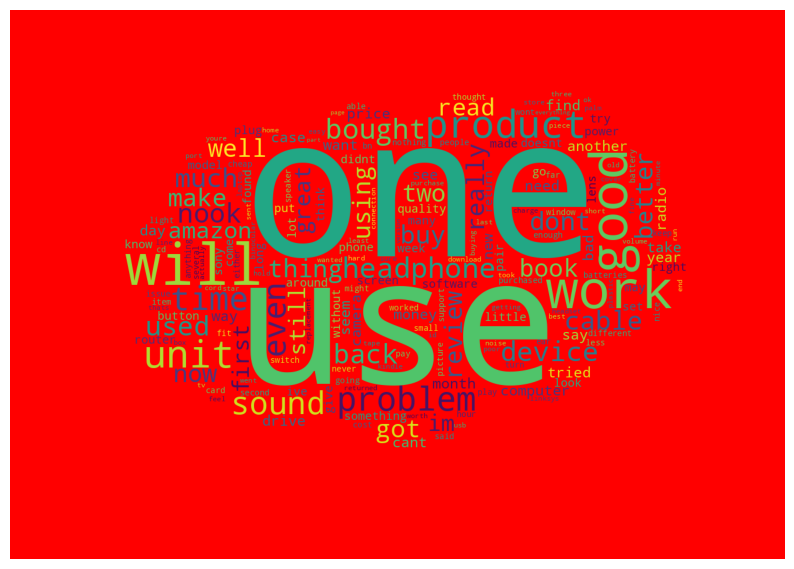

In [45]:
wc(negative,'red')

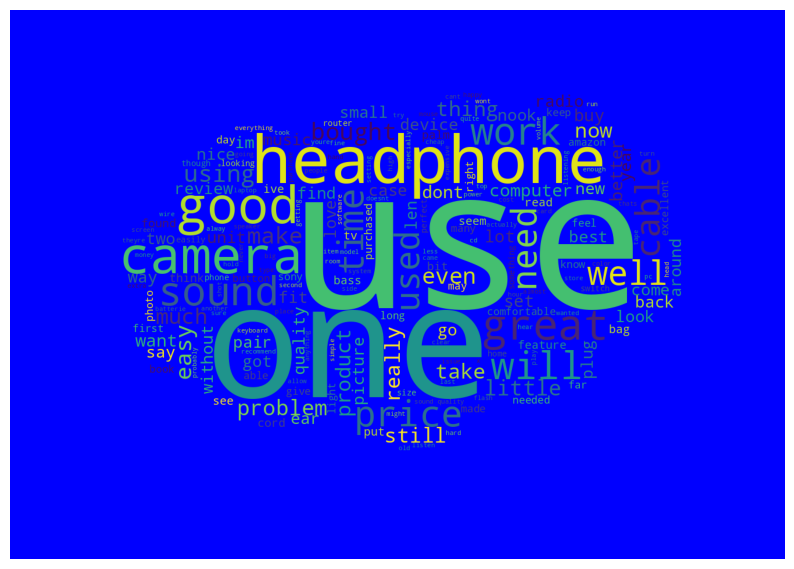

In [46]:
wc(positive,'blue')

In [47]:
x=df["reviewText"]
y=df['sentiment']

In [48]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [49]:
from sklearn.feature_extraction.text import CountVectorizer

In [50]:
from textblob import TextBlob
from nltk.stem import PorterStemmer
pr=PorterStemmer()

In [51]:
def lemmafn(reviewText): #Kelimelerin eklerini kaldırıp köklerini bulan fonksiyon
    words=TextBlob(reviewText).words
    return [pr.stem(word) for word in words]

In [52]:
vect=CountVectorizer(stop_words='english', ngram_range=(1,2),analyzer=lemmafn)

In [54]:
import nltk
nltk.download('punkt')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


True

In [55]:
x=vect.fit_transform(x)

In [56]:
from sklearn.model_selection import train_test_split

In [57]:
x_train, x_test, y_train, y_test=train_test_split(x,y,random_state=42, test_size=0.20)

In [58]:
nb=MultinomialNB()

In [59]:
model=nb.fit(x_train,y_train)

In [60]:
tahmin=model.predict(x_test)

In [61]:
accuracy_score(tahmin,y_test)

0.8215982721382289

In [62]:
tahmin

array([2, 2, 2, ..., 2, 2, 2])

In [63]:
from sklearn.linear_model import LogisticRegression

In [64]:
lr=LogisticRegression()

In [65]:
model=lr.fit(x_train,y_train)

/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [66]:
lr_tahmin=lr.predict(x_test)

In [67]:
accuracy_score(lr_tahmin,y_test)

0.8241900647948164

In [68]:
from sklearn.naive_bayes import BernoulliNB

In [69]:
b=BernoulliNB()

In [70]:
model=b.fit(x_train,y_train)

In [71]:
tahmin=b.predict(x_test)

In [72]:
accuracy_score(tahmin,y_test)

0.7740820734341253

In [73]:
from sklearn.ensemble import RandomForestClassifier

In [74]:
r=RandomForestClassifier()

In [75]:
model=r.fit(x_train,y_train)

In [76]:
tahmin=r.predict(x_test)

In [77]:
accuracy_score(tahmin,y_test)

0.8215982721382289

In [78]:
from sklearn.tree import DecisionTreeClassifier

In [79]:
d=DecisionTreeClassifier()

In [80]:
model=d.fit(x_train,y_train)

In [81]:
tahmin=d.predict(x_test)

In [82]:
accuracy_score(tahmin,y_test)

0.7576673866090713

In [83]:
confusion_matrix(lr_tahmin,y_test)

array([[  37,   22,   77],
       [  39,  109,   60],
       [ 123,   86, 1762]])